In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))   # pour pouvoir importer des fonctions depuis utils qui est à la racine

import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from torch.utils.data import DataLoader
import os
from utils import get_device, ImageDataset, random_90_rotation

In [3]:
device = get_device()
print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [4]:
batch_size = 512
num_epochs = 10
num_classes = 5
num_attributs = 60
crop_size = 32

In [5]:
transform = transforms.Compose([
    # transforms.RandomHorizontalFlip(p=0.5),
    # transforms.RandomVerticalFlip(p=0.5),
    # transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(partial_path="../data/dataset_crops/train_32x32", transform=transform)
val_dataset = ImageDataset(partial_path="../data/dataset_crops/val_32x32", transform=transform)

print(f"taille de train_dataset : {len(train_dataset)}   taille de val_dataset : {len(val_dataset)}")

taille de train_dataset : 455135   taille de val_dataset : 99236


In [6]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=8)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [7]:
from torchvision.models import resnet18

resnet = resnet18()
# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, num_attributs)

# load the resnet parameters
checkpoint = torch.load("weights/imgs_to_attributs_32x32_checkpoint.pth", map_location="cpu")
resnet.load_state_dict(checkpoint["model_state_dict"])

resnet = resnet.to(device)
resnet.eval()

print(f"Total parameters in the model: {sum(p.numel() for p in resnet.parameters())/1e6:.6f} million")

Total parameters in the model: 11.207292 million


In [8]:
fully_connected = nn.Linear(num_attributs, num_classes).to(device)

# load the fully_connected parameters
checkpoint = torch.load("weights/attributs_to_classes_32x32_checkpoint.pth", map_location="cpu")
fully_connected.load_state_dict(checkpoint["model_state_dict"])

print(f"Total parameters in the model: {sum(p.numel() for p in fully_connected.parameters())/1e6:.6f} million")

Total parameters in the model: 0.000305 million


100%|██████████| 194/194 [00:13<00:00, 14.35it/s]


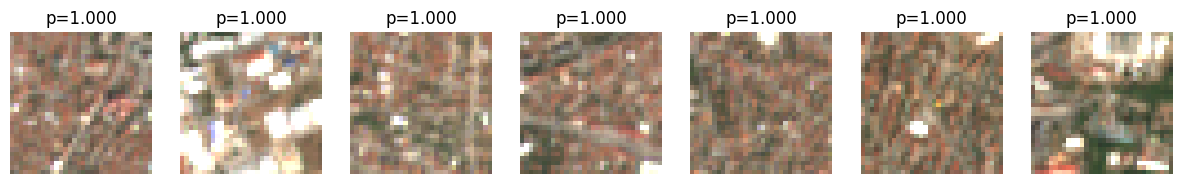

In [10]:
# CODE POUR TROUVER LES IMAGES QUI CORRESPONDENT À L'ACTIVATION D'UN ATTRIBUT

attribut_index = 19    # zones très construites

top_k = 7
top_probs = []
top_imgs = []

for i, (imgs, attributs, classes) in tqdm(enumerate(val_loader), total=len(val_loader)):
    
    imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

    with torch.no_grad():
        attributs_pred = resnet(imgs)

        # find the probability of the attribut we are looking for
        probs = torch.sigmoid(attributs_pred[:, attribut_index])

        # mettre à jour le top-k
        for j, p in enumerate(probs):
            if len(top_probs) < top_k:
                top_probs.append(p.item())
                top_imgs.append(imgs[j].detach().cpu())
            else:
                min_idx = int(torch.argmin(torch.tensor(top_probs)))
                if p.item() > top_probs[min_idx]:
                    top_probs[min_idx] = p.item()
                    top_imgs[min_idx] = imgs[j].detach().cpu()


# Trier les résultats du plus grand au plus petit
sorted_indices = sorted(range(len(top_probs)), key=lambda k: top_probs[k], reverse=True)
top_probs = [top_probs[k] for k in sorted_indices]
top_imgs  = [top_imgs[k] for k in sorted_indices]


# Affichage des images
fig, axes = plt.subplots(1, top_k, figsize=(15,5))
for idx, ax in enumerate(axes):
    img = top_imgs[idx]
    img = img.permute(1, 2, 0)  # (C,H,W) -> (H,W,C)
    ax.imshow((img+1)/2)
    ax.set_title(f"p={top_probs[idx]:.3f}")
    ax.axis("off")

plt.show()